# KA1 Milestone 1: Research Design and Feasibility
## BRFSS 2024 frequent mental distress
**Researcher:** Ngozichukwuka Ejiofor

Exploratory and feasibility work for the initial assignment. It documents the source, measurement, target balance, missingness, predictor distributions, leakage checks, and feasibility of the proposed state-held-out design. It does not fit or compare predictive models.


## 1. Settings and software
This is an exploratory notebook.


In [9]:
from pathlib import Path
import os, sys, json, platform, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
try:
    from IPython.display import display, Markdown
except ImportError:
    def display(value): print(value)
    def Markdown(value): return value
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42
N_FOLDS = 5
DATA_PATH = Path(os.environ.get('BRFSS_PATH', 'LLCP2024.XPT'))
OUTPUT_DIR = Path('ka1_aggregate_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.figsize': (8, 4.5), 'axes.spines.top': False, 'axes.spines.right': False})
software = {'Python':platform.python_version(), 'NumPy':np.__version__,
            'pandas':pd.__version__, 'scikit-learn':sklearn.__version__}
display(pd.DataFrame(software.items(), columns=['Software', 'Version']))


,Software,Version
0,Python,3.14.7
1,NumPy,2.5.3
2,pandas,3.0.5
3,scikit-learn,1.9.0


## 2. Load and audit the source
**Attribution:** CDC, [2024 BRFSS survey data and documentation](https://www.cdc.gov/brfss/annual_data/annual_2024.html). 



In [22]:
DATA_PATH = Path(
    "/Users/honeydrops/Library/Mobile Documents/"
    "com~apple~CloudDocs/Documents/Harrisburg University/"
    "Classes/Fall 2026/ANLY 530/Project/"
    "brfss-mental-distress-ka1/LLCP2024.XPT"
)

with DATA_PATH.open("rb") as stream:
    input_sha256 = hashlib.file_digest(stream, "sha256").hexdigest()

raw = pd.read_sas(DATA_PATH, format="xport", encoding="utf-8")

print("Input shape:", raw.shape)
print("Input SHA-256:", input_sha256)

Input shape: (457670, 301)
Input SHA-256: 7d53cf088f858e02bcc029a51cf0408cc68f40a0ebeb02a3c0f73058aab36b1c


In [11]:
NUMERIC = ['_AGE80', '_BMI5', 'PHYSHLTH']
CATEGORICAL = ['SEXVAR', 'EDUCA', 'INCOME3', 'EMPLOY1', 'CHECKUP1', '_TOTINDA', '_SMOKER3', 'DIFFWALK']
FEATURES = NUMERIC + CATEGORICAL
VALID = {'_AGE80': range(18, 81), 'SEXVAR': [1, 2], 'EDUCA': range(1, 7),
         'INCOME3': range(1, 12), 'EMPLOY1': range(1, 9), 'CHECKUP1': [1, 2, 3, 4, 8],
         '_TOTINDA': [1, 2], '_SMOKER3': [1, 2, 3, 4], 'DIFFWALK': [1, 2]}


def clean(raw):
    required = FEATURES + ['MENTHLTH', '_STATE', '_LLCPWT']
    absent = sorted(set(required) - set(raw.columns))
    if absent:
        raise ValueError(f'Missing required fields: {absent}. Check the matching file/codebook; do not substitute silently.')
    d = raw[required].copy()
    days = pd.to_numeric(d['MENTHLTH'], errors='coerce').replace(88, 0)
    d['target'] = np.where(days.between(0, 30), (days >= 14).astype(float), np.nan)
    for col in FEATURES:
        d[col] = pd.to_numeric(d[col], errors='coerce')
    for col, values in VALID.items():
        d[col] = d[col].where(d[col].isin(values))
    d['PHYSHLTH'] = d['PHYSHLTH'].replace(88, 0)
    d['PHYSHLTH'] = d['PHYSHLTH'].where(d['PHYSHLTH'].between(0, 30))
    d['_BMI5'] = d['_BMI5'].where(np.isfinite(d['_BMI5']) & (d['_BMI5'] > 0)) / 100
    d['_LLCPWT'] = pd.to_numeric(d['_LLCPWT'], errors='coerce')
    missing = pd.DataFrame({'variable': FEATURES,
                            'raw_missing_n': raw[FEATURES].isna().sum().to_numpy(),
                            'recoded_missing_n': d[FEATURES].isna().sum().to_numpy()})
    eligible = d['target'].notna() & d['_STATE'].notna() & np.isfinite(d['_LLCPWT']) & (d['_LLCPWT'] > 0)
    result = d.loc[eligible].drop(columns='MENTHLTH').reset_index(drop=True)
    if result.empty:
        raise ValueError('No eligible rows after target/design checks.')
    summary = {'input_n': len(raw), 'valid_target_n': int(d['target'].notna().sum()),
               'eligible_n': len(result), 'excluded_n': int((~eligible).sum()),
               'positive_n': int(result.target.sum()), 'unweighted_prevalence': float(result.target.mean()),
               'weighted_prevalence': float(np.average(result.target, weights=result['_LLCPWT'])),
               'states_or_territories': int(result['_STATE'].nunique())}
    return result, missing, summary



In [12]:
required = FEATURES + ['MENTHLTH', '_STATE', '_LLCPWT']
availability = pd.DataFrame({'variable': required,
    'available': [v in raw for v in required],
    'raw_missing_pct': [raw[v].isna().mean()*100 if v in raw else np.nan for v in required]})
display(availability.round(2))
print('Excluded unavailable predictors from earlier work: HLTHPL1 and SLEPTIM1.')
print('Design fields are not used as predictors: _LLCPWT, _STATE, _PSU, _STSTR.')


,variable,available,raw_missing_pct
0,_AGE80,True,0.00
1,_BMI5,True,9.40
2,PHYSHLTH,True,0.00
3,SEXVAR,True,0.00
4,EDUCA,True,0.00
5,INCOME3,True,2.03
6,EMPLOY1,True,0.72
7,CHECKUP1,True,0.00
8,_TOTINDA,True,0.00
9,_SMOKER3,True,0.00


Excluded unavailable predictors from earlier work: HLTHPL1 and SLEPTIM1.
Design fields are not used as predictors: _LLCPWT, _STATE, _PSU, _STSTR.


## 3. Define the target, clean codes, and document exclusions
Frequent mental distress is **14–30 mentally unhealthy days in the preceding 30 days**; the comparison group is 0–13 days. `MENTHLTH=88` means zero days. Codes 77, 99, invalid values, and missing outcomes are excluded, never imputed.

The eleven predictors match the corrected earlier analysis. BMI is divided by 100; PHYSHLTH=88 is zero. Unknown/refused categorical codes are missing, while CHECKUP1=8 (never had a routine checkup) remains valid. Predictor missingness is retained for training-fold imputation.


In [13]:
cleaned, missingness, cohort = clean(raw)
mental_days = pd.to_numeric(raw['MENTHLTH'], errors='coerce').replace(88, 0)
valid_target = mental_days.between(0, 30)
weights_raw = pd.to_numeric(raw['_LLCPWT'], errors='coerce')
valid_weight = np.isfinite(weights_raw) & weights_raw.gt(0)
valid_state = raw['_STATE'].notna()
flow = pd.DataFrame([
    ['Input respondents', len(raw)],
    ['Valid mental-health response', int(valid_target.sum())],
    ['Valid target and positive finite weight', int((valid_target & valid_weight).sum())],
    ['Final eligible cohort with state', len(cleaned)]], columns=['Stage','N'])
display(flow)
display(pd.DataFrame(cohort.items(),columns=['Measure','Value']))
print('Predictor missingness does not cause respondent exclusion here.')
print('Duplicate response patterns are not assumed to be duplicate people.')


,Stage,N
0,Input respondents,457670
1,Valid mental-health response,449514
2,Valid target and positive finite weight,449514
3,Final eligible cohort with state,449514


,Measure,Value
0,input_n,457670.000000
1,valid_target_n,449514.000000
2,eligible_n,449514.000000
3,excluded_n,8156.000000
4,positive_n,62315.000000
5,unweighted_prevalence,0.138627
6,weighted_prevalence,0.155220
7,states_or_territories,53.000000


Predictor missingness does not cause respondent exclusion here.
Duplicate response patterns are not assumed to be duplicate people.


,variable,raw_missing_n,recoded_missing_n,raw_missing_pct,recoded_missing_pct_all_input,eligible_missing_pct
0,_AGE80,0,0,0.00,0.00,0.00
1,_BMI5,43037,43037,9.40,9.40,9.24
2,PHYSHLTH,5,11067,0.00,2.42,1.92
3,SEXVAR,0,0,0.00,0.00,0.00
4,EDUCA,7,2363,0.00,0.52,0.47
5,INCOME3,9269,87423,2.03,19.10,18.72
6,EMPLOY1,3303,8402,0.72,1.84,1.76
7,CHECKUP1,2,5334,0.00,1.17,1.08
8,_TOTINDA,0,1315,0.00,0.29,0.24
9,_SMOKER3,0,32022,0.00,7.00,6.91


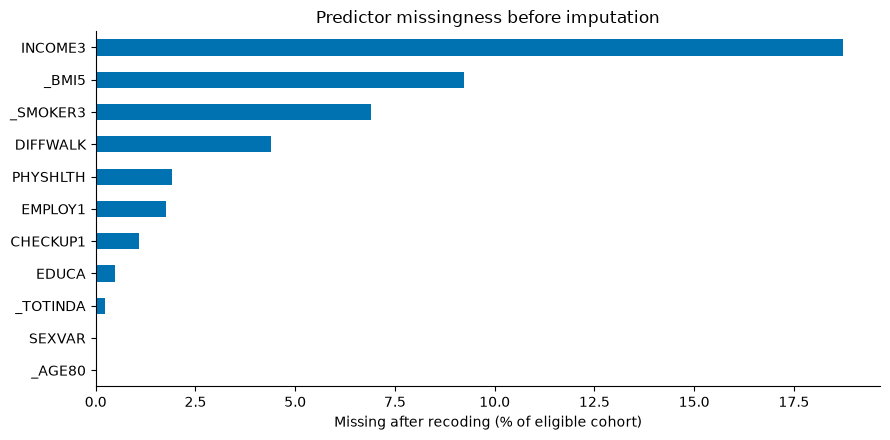

Interpretation: coded nonresponses can increase missingness beyond the raw NaN count. Imputation will be learned inside each training fold.


In [14]:
missingness['raw_missing_pct'] = missingness['raw_missing_n']/len(raw)*100
missingness['recoded_missing_pct_all_input'] = missingness['recoded_missing_n']/len(raw)*100
missingness['eligible_missing_pct'] = cleaned[FEATURES].isna().mean().to_numpy()*100
display(missingness.round(2))
fig, ax = plt.subplots(figsize=(9,4.5))
missingness.sort_values('eligible_missing_pct').plot.barh(x='variable',y='eligible_missing_pct',ax=ax,legend=False,color='#0072B2')
ax.set(xlabel='Missing after recoding (% of eligible cohort)', ylabel='',title='Predictor missingness before imputation')
plt.tight_layout(); plt.show()
print('Interpretation: coded nonresponses can increase missingness beyond the raw NaN count. Imputation will be learned inside each training fold.')


## 4. Outcome balance and descriptive exploration
Report both respondent counts and survey-weighted prevalence. They answer different questions: the sample fraction is not automatically the population estimate. AP is reported later alongside its corresponding prevalence. Descriptive statistics here do not select predictors or model parameters.


,Target,Description,Respondent_n,Sample_percent,Survey_weighted_percent
0,0,0–13 days,387199,86.137,84.478
1,1,14–30 days,62315,13.863,15.522


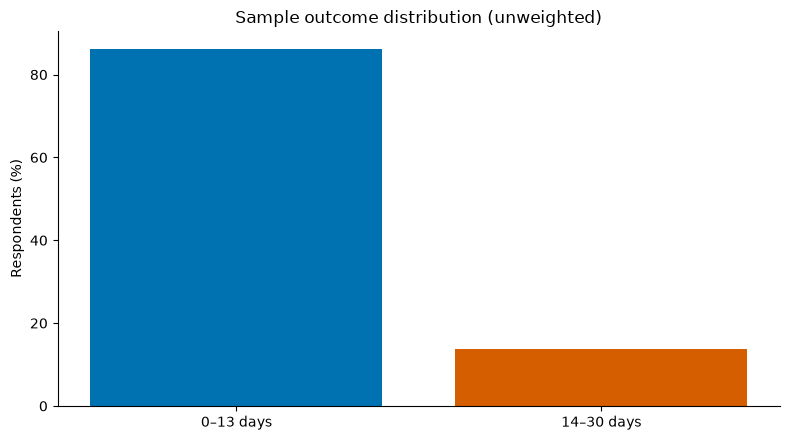

Unweighted prevalence: 13.86%; survey-weighted prevalence: 15.52%.
A classifier predicting no distress for everyone has sample accuracy 86.14% but zero sensitivity for distress.


In [15]:
y_full = cleaned.target.astype(int)
w_full = cleaned['_LLCPWT']
target_table = pd.DataFrame({'Target':[0,1], 'Description':['0–13 days','14–30 days']})
target_table['Respondent_n'] = [int((y_full==k).sum()) for k in [0,1]]
target_table['Sample_percent'] = target_table.Respondent_n/len(cleaned)*100
target_table['Survey_weighted_percent'] = [np.average(y_full==k,weights=w_full)*100 for k in [0,1]]
display(target_table.round(3))
fig, ax = plt.subplots()
ax.bar(['0–13 days','14–30 days'], target_table.Sample_percent, color=['#0072B2','#D55E00'])
ax.set(ylabel='Respondents (%)',title='Sample outcome distribution (unweighted)')
plt.tight_layout();plt.show()
print(f'Unweighted prevalence: {y_full.mean():.2%}; survey-weighted prevalence: {np.average(y_full,weights=w_full):.2%}.')
print(f'A classifier predicting no distress for everyone has sample accuracy {(y_full==0).mean():.2%} but zero sensitivity for distress.')


,count,mean,std,min,25%,50%,75%,max
Age (top-coded at 80),449514.0,55.04,18.12,18.0,40.00,58.00,70.00,80.00
BMI (kg/m²),407974.0,28.56,6.58,12.0,24.14,27.44,31.75,99.84
Physically unhealthy days,440903.0,4.57,8.89,0.0,0.00,0.00,4.00,30.00


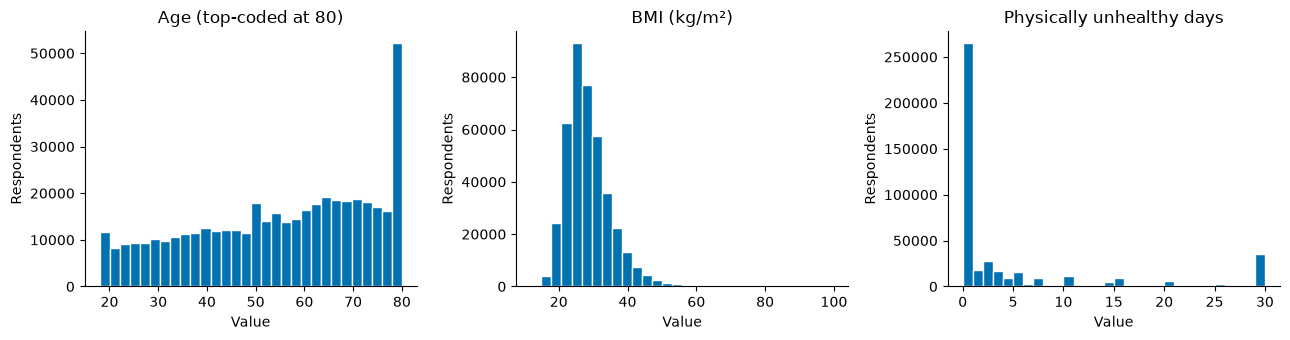

These summaries are unweighted descriptions of the eligible sample. Check extremes against the codebook rather than automatically deleting them.


In [16]:
labels = {'_AGE80':'Age (top-coded at 80)', '_BMI5':'BMI (kg/m²)', 'PHYSHLTH':'Physically unhealthy days'}
numeric_summary = cleaned[NUMERIC].describe(percentiles=[.25,.5,.75]).T
numeric_summary.index = [labels[c] for c in numeric_summary.index]
display(numeric_summary.round(2))
fig, axes = plt.subplots(1,3,figsize=(13,3.5))
for ax,col in zip(axes,NUMERIC):
    values=cleaned[col].dropna()
    ax.hist(values,bins=30,color='#0072B2',edgecolor='white')
    ax.set(title=labels[col],xlabel='Value',ylabel='Respondents')
plt.tight_layout();plt.show()
print('These summaries are unweighted descriptions of the eligible sample. Check extremes against the codebook rather than automatically deleting them.')


In [17]:
# Aggregate category-code frequencies; unknowns remain explicitly visible.
category_rows=[]
for col in CATEGORICAL:
    values=cleaned[col].fillna('Missing').astype(str)
    for category,n in values.value_counts().items():
        category_rows.append({'Predictor':col,'Code (see codebook)':category,'N':int(n),'Sample_percent':100*n/len(cleaned)})
category_summary=pd.DataFrame(category_rows)
display(category_summary.round(2))
# No individual rows are displayed or saved.


,Predictor,Code (see codebook),N,Sample_percent
0,SEXVAR,2.0,235858,52.47
1,SEXVAR,1.0,213656,47.53
2,EDUCA,6.0,189554,42.17
3,EDUCA,5.0,118611,26.39
4,EDUCA,4.0,113211,25.19
5,EDUCA,3.0,16567,3.69
6,EDUCA,2.0,8767,1.95
7,EDUCA,Missing,2133,0.47
8,EDUCA,1.0,671,0.15
9,INCOME3,Missing,84161,18.72


,Distress,Predictor,Observed_n,Sample_median,Weighted_mean
0,0,Age (top-coded at 80),387199,59.00,49.213
1,0,BMI (kg/m²),350849,27.39,28.274
2,0,Physically unhealthy days,380032,0.00,3.173
3,1,Age (top-coded at 80),62315,49.00,42.908
4,1,BMI (kg/m²),57125,28.32,29.509
5,1,Physically unhealthy days,60871,5.00,10.199


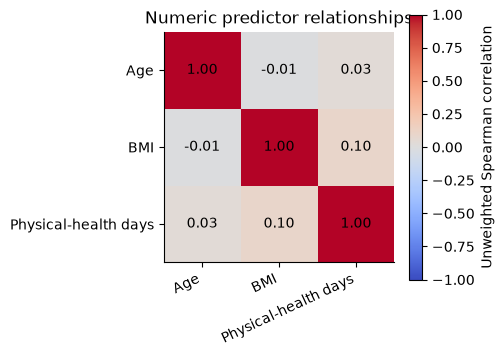

Associations with distress do not identify causal effects. Physical health and mental health refer to the same recall window; excluding PHYSHLTH is a planned sensitivity analysis.


In [18]:
profile_rows=[]
for group,part in cleaned.groupby('target'):
    for col in NUMERIC:
        ok=part[col].notna()
        profile_rows.append({'Distress':int(group),'Predictor':labels[col],
                            'Observed_n':int(ok.sum()),
                            'Sample_median':part.loc[ok,col].median(),
                            'Weighted_mean':np.average(part.loc[ok,col],weights=part.loc[ok,'_LLCPWT']) if ok.any() else np.nan})
display(pd.DataFrame(profile_rows).round(3))
corr=cleaned[NUMERIC].corr(method='spearman')
fig,ax=plt.subplots(figsize=(5,4))
im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(3),['Age','BMI','Physical-health days'],rotation=25,ha='right')
ax.set_yticks(range(3),['Age','BMI','Physical-health days'])
for i in range(3):
    for j in range(3):ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center')
fig.colorbar(im,ax=ax,label='Unweighted Spearman correlation')
ax.set_title('Numeric predictor relationships');plt.tight_layout();plt.show()
print('Associations with distress do not identify causal effects. Physical health and mental health refer to the same recall window; excluding PHYSHLTH is a planned sensitivity analysis.')


## 5. Sampling design and leakage checks
The earlier state–PSU identifier was effectively unique per respondent, so it could not create meaningful grouped validation. Here, entire states/territories are held out. This tests geographic transfer within the survey year, not temporal or clinical validity. Survey weighting and state separation address different issues.

All models use the same folds. No target-derived measurement, state, or survey identifier enters the predictor matrix. Missingness handling and scaling are fitted only on the training portion of each fold. Descriptive full-cohort exploration must not be used to keep changing the design based on validation results.


In [19]:
forbidden = {'MENTHLTH','mental_health_days','_MENT14D','target','frequent_mental_distress','_STATE','_PSU','_STSTR','_LLCPWT'}
assert forbidden.isdisjoint(FEATURES)
assert len(FEATURES)==11
if {'_STATE','_PSU'}.issubset(raw.columns):
    pair_n=raw[['_STATE','_PSU']].dropna().drop_duplicates().shape[0]
    observed_pair_n=raw[['_STATE','_PSU']].dropna().shape[0]
    print('Unique state–PSU pairs:',pair_n,'of',observed_pair_n,'nonmissing records.')
    if pair_n==observed_pair_n:
        print('Pairs are unique per respondent: this identifier does not create repeated respondent groups.')
X=cleaned[FEATURES]
y=cleaned.target.astype(int)
w=cleaned['_LLCPWT'].astype(float)
states=cleaned['_STATE']
if states.nunique()<N_FOLDS:
    raise ValueError('Insufficient states for the proposed fold count; revise the design before modeling.')
splits=list(StratifiedGroupKFold(n_splits=N_FOLDS,shuffle=True,random_state=SEED).split(X,y,groups=states))
fold_rows=[]
for fold,(tr,va) in enumerate(splits,1):
    assert set(states.iloc[tr]).isdisjoint(set(states.iloc[va]))
    fold_rows.append({'Proposed_fold':fold,'Training_n':len(tr),'Validation_n':len(va),
        'Heldout_states_n':states.iloc[va].nunique(),'State_overlap_n':0,
        'Training_classes_n':y.iloc[tr].nunique(),'Validation_classes_n':y.iloc[va].nunique(),
        'Validation_weighted_prevalence':np.average(y.iloc[va],weights=w.iloc[va])})
fold_audit=pd.DataFrame(fold_rows)
display(fold_audit.round(4))
if not (fold_audit.Training_classes_n.eq(2) & fold_audit.Validation_classes_n.eq(2)).all():
    raise ValueError('A proposed fold has one outcome class. Revise the split design before modeling.')
print('Proposed splits are feasible: no state overlap and both classes present. No model has been fitted.')


Unique state–PSU pairs: 457670 of 457670 nonmissing records.
Pairs are unique per respondent: this identifier does not create repeated respondent groups.


,Proposed_fold,Training_n,Validation_n,Heldout_states_n,State_overlap_n,Training_classes_n,Validation_classes_n,Validation_weighted_prevalence
0,1,359243,90271,9,0,2,2,0.1461
1,2,360977,88537,10,0,2,2,0.1598
2,3,359264,90250,11,0,2,2,0.1561
3,4,359633,89881,12,0,2,2,0.1574
4,5,358939,90575,11,0,2,2,0.1597


Proposed splits are feasible: no state overlap and both classes present. No model has been fitted.


## 6. Save reproducibility records and aggregate exploratory tables
Only aggregate summaries and the analysis manifest are exported. No respondent records or row-level outcomes/predictions are saved. Keep the output directory local unless you intentionally review individual aggregate files for publication.


In [20]:
manifest={'project':'BRFSS KA1 initial research design and feasibility','seed':SEED,
    'input_sha256':input_sha256,'input_shape':list(raw.shape),'software':software,
    'features':FEATURES,'cohort':cohort,'planned_validation':'Five state-held-out folds',
    'models_fitted':False,'status':'Exploration and split-feasibility checks only'}
(OUTPUT_DIR/'initial_analysis_manifest.json').write_text(json.dumps(manifest,indent=2))
for filename,table in [('cohort_flow.csv',flow),('predictor_missingness.csv',missingness),
                       ('target_distribution.csv',target_table),('numeric_summary.csv',numeric_summary.reset_index()),
                       ('category_summary.csv',category_summary),('proposed_state_folds.csv',fold_audit)]:
    table.to_csv(OUTPUT_DIR/filename,index=False)
print('Saved aggregate feasibility summaries to:',OUTPUT_DIR.name)
print('No respondent data or predictions exported.')


Saved aggregate feasibility summaries to: ka1_aggregate_outputs
No respondent data or predictions exported.


## 7. Initial-assignment conclusion and proposed next steps
The exploratory analysis confirmed that the BRFSS file could be loaded and that all eleven selected predictors were available. It documented the outcome definition, eligible sample, weighted and unweighted prevalence, and missing-response patterns. Outcome-derived information was excluded from the predictors. The proposed validation folds contained both outcome classes and kept states separate, supporting the feasibility of the evaluation plan.

The next stage will compare a constant training-prevalence baseline, L2 logistic regression, and a decision tree with limits on its complexity. All models will use the same state-held-out folds, with preprocessing learned from training data only. Survey weights will be used for fitting and primary evaluation. Later work will include tuning, calibration, threshold selection, subgroup comparisons, and uncertainty assessment.

These data describe self-reported health at one point in time. They cannot establish causes of distress or predict future onset. Nonresponse, measurement error, missing information, and incomplete population coverage may affect the findings. Geographic validation within 2024 will not establish performance in future years or clinical settings.



In [21]:
display(Markdown(f"**Feasibility summary:** The input contains {len(raw):,} records and {raw.shape[1]} columns. "
    f"After target and design-field eligibility checks, {len(cleaned):,} respondents remain. "
    f"Frequent mental distress affects {cleaned.target.mean():.2%} of the eligible sample; "
    f"survey-weighted prevalence is {np.average(cleaned.target,weights=cleaned['_LLCPWT']):.2%}. "
    "The selected predictors, missingness, and proposed state-held-out folds have been audited. "
    "This establishes an executable exploratory workflow; no predictive models have been fitted."))


**Feasibility summary:** The input contains 457,670 records and 301 columns. After target and design-field eligibility checks, 449,514 respondents remain. Frequent mental distress affects 13.86% of the eligible sample; survey-weighted prevalence is 15.52%. The selected predictors, missingness, and proposed state-held-out folds have been audited. This establishes an executable exploratory workflow; no predictive models have been fitted.

## Sources
**Data:** Centers for Disease Control and Prevention. (n.d.). *2024 BRFSS survey data and documentation*. https://www.cdc.gov/brfss/annual_data/annual_2024.html

Moriarty, D. G., Zack, M. M., & Kobau, R. (2003). The Centers for Disease Control and Prevention’s Healthy Days Measures: Population tracking of perceived physical and mental health over time. *Health and Quality of Life Outcomes, 1*, 37. https://doi.org/10.1186/1477-7525-1-37

